# Comparación reproc / normalización — ROI patch

Efecto de **cambiar el preprocesado de entrada** y la **forma de normalizar** MRI/SPECT, manteniendo la misma receta E2:
calibración latente + canal ROI UNet (`roi3ch`) + **ruido uniforme** (`HIGH_T_SAMPLE_PROB=0`).

## Alcance actual (importante)

Los pares full-brain reproc **no están en disco**:

- `calib_roi3ch_uni_reproc`
- `calib_roi3ch_uni_reproc_v2load`

Por tanto **no tiene sentido** incluir el baseline full-brain `calib_roi3ch_uni` en este reporte: quedaría solo, sin contraste de normalización/preproceso dentro del mismo dominio. Ese baseline se **excluye** del análisis activo.

Este notebook compara **solo ROI patch** (`data_rois/`), donde sí existen las tres celdas del factorial:

| Clave | Dominio | Datos | Carga (`IMAGE_VOLUME_NORM`) |
|-------|---------|-------|-----------------------------|
| `calib_roi3ch_uni_rois` | ROI patch | legacy `data_rois/` | legacy (z-score volumen) — **baseline** |
| `calib_roi3ch_uni_rois_reproc` | ROI patch | reproc `data_rois/` | **legacy** — z-score MRI+SPECT |
| `calib_roi3ch_uni_rois_reproc_v2load` | ROI patch | reproc `data_rois/` | **v2load** — MRI `>0`; SPECT sin z-score |

**Fuera de alcance hasta que existan resultados:** `calib_roi3ch_uni`, `calib_roi3ch_uni_reproc`, `calib_roi3ch_uni_reproc_v2load`.

**Métrica primaria:** balanced accuracy / AUC en clasificación de latentes DDIM (test).
PSNR/SSIM secundarios.

Secciones:
1. Convergencia en entrenamiento
2. Reconstrucción en test
3. Clasificación en test
4. Deltas vs baseline ROI + síntesis
5. Visualizaciones (mismos sujetos)


**Apéndice §6:** comparación full-brain aparte `calib_fb_clamp` (baseline) vs `calib_fb_v2` (EMA/attn/FiLM). No confundir con el factorial ROI de arriba.

Export: `result/reproc_norm_comparison_summary/`.
Estructura alineada con `code/stage2_experiments_report.ipynb`.


## 0. Configuración

In [3]:
import os

os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")

'0'

In [4]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, here.parent):
        if (candidate / "result").is_dir() and (candidate / "code" / "stage2_report_utils.py").is_file():
            return candidate
    raise RuntimeError(
        "No se encontró la raíz del repo. Ejecuta desde IL-CLDM/ o IL-CLDM/code/."
    )


ROOT = find_repo_root()
os.chdir(ROOT)
root_str = str(ROOT)
if root_str in sys.path:
    sys.path.remove(root_str)
sys.path.insert(0, root_str)

import importlib

for _mod_name in list(sys.modules):
    if _mod_name in ("code", "code.stage2_report_utils") or _mod_name.endswith("stage2_report_utils"):
        del sys.modules[_mod_name]
if "code" in sys.modules and not hasattr(sys.modules.get("code"), "__path__"):
    del sys.modules["code"]

import code.stage2_report_utils as stage2_report_utils

importlib.reload(stage2_report_utils)
from code.stage2_report_utils import (
    LABEL_NAMES,
    available_comparison,
    colors_for_modes,
    domain_buckets_for_modes,
    load_classification_metrics_for,
    load_inference_reconstruction_for,
    load_registry,
    load_synthetic_volume_for,
    load_test_ids,
    load_training_frames_for,
    manifest_summary_table,
    pick_stratified_subjects,
    repo_root,
    short_labels_for_modes,
    subset_by_modes,
    training_checkpoint_summary,
)
from viz_pairs import load_cropped

# --- Factorial reproc / norm ---
# Solo ROI: full-brain reproc ausente → excluir baseline full-brain (no comparable).
WAVE_ORDER = (
    "calib_roi3ch_uni_rois",
    "calib_roi3ch_uni_rois_reproc",
    "calib_roi3ch_uni_rois_reproc_v2load",
)
# Documentados pero no analizados (faltan reproc full-brain en result/).
FULLBRAIN_PENDING = (
    "calib_roi3ch_uni",
    "calib_roi3ch_uni_reproc",
    "calib_roi3ch_uni_reproc_v2load",
)
DOMAIN_BASELINE = {
    "data_rois": "calib_roi3ch_uni_rois",
}
NORM_FAMILY = {
    "calib_roi3ch_uni": "legacy_data",
    "calib_roi3ch_uni_rois": "legacy_data",
    "calib_roi3ch_uni_reproc": "reproc_legacy_zscore",
    "calib_roi3ch_uni_rois_reproc": "reproc_legacy_zscore",
    "calib_roi3ch_uni_reproc_v2load": "reproc_v2load",
    "calib_roi3ch_uni_rois_reproc_v2load": "reproc_v2load",
}
EXPORT_DIR_NAME = "reproc_norm_comparison_summary"
_REGISTRY = load_registry()["experiments"]
_BASES = load_registry()


def _mode_split_profile(mode_key: str) -> str:
    return _REGISTRY[mode_key].get("split_profile", "primary")


def data_root_for_mode(mode_key: str) -> Path:
    if _mode_split_profile(mode_key) == "data_rois":
        return repo_root() / "data_rois"
    return repo_root() / "data"


def image_norm_for_mode(mode_key: str) -> str:
    base_name = _REGISTRY[mode_key].get("base")
    base = _BASES.get(base_name, {}) if base_name else {}
    env = {**base, **_REGISTRY[mode_key].get("overrides", {})}
    return str(env.get("ILCLDM_IMAGE_VOLUME_NORM", "legacy"))


def load_gt_spect_for_mode(mode_key: str, subject_id: str) -> np.ndarray:
    root = data_root_for_mode(mode_key) / "whole_Abeta"
    if _mode_split_profile(mode_key) == "data_rois":
        from dataset import nifti_to_numpy, resolve_nifti_path

        zscore = image_norm_for_mode(mode_key) != "v2load"
        return nifti_to_numpy(str(resolve_nifti_path(str(root), subject_id)), zscore=zscore)
    return load_cropped(root, subject_id)


def _subset_wave(pool, order):
    return {k: pool[k] for k in order if k in pool}


def _with_registry_meta(comparison):
    out = {}
    for key, cfg in comparison.items():
        entry = dict(cfg)
        reg = _REGISTRY[key]
        entry["short_label"] = reg.get("short_label", key)
        entry["label"] = reg.get("label", entry.get("label", key))
        entry["early_stop"] = reg.get("early_stop", entry.get("early_stop", "image"))
        entry["split_profile"] = reg.get("split_profile", "primary")
        entry["norm_family"] = NORM_FAMILY.get(key, "unknown")
        entry["image_norm"] = image_norm_for_mode(key)
        out[key] = entry
    return out


def available_wave_comparison(pool=None):
    return _with_registry_meta(_subset_wave(pool or available_comparison(), WAVE_ORDER))


def load_test_ids_for_mode(mode_key: str) -> list[str]:
    return [line.strip() for line in (repo_root() / "data_info" / "test.txt").read_text().splitlines() if line.strip()]


def validate_wave_comparison(pool=None):
    warnings: list[str] = []
    comparison = available_wave_comparison(pool)
    for mode_key, cfg in comparison.items():
        exp_name = cfg["exp"]
        run_id = cfg["run_id"]
        test_ids = set(load_test_ids_for_mode(mode_key))
        root = repo_root() / "result" / exp_name
        for fname in ("loss_curve.csv", "validation.csv", "test.csv"):
            if not (root / fname).exists():
                warnings.append(f"Missing {root / fname}")
        inf = root / "inference" / run_id
        recon_path = inf / "reconstruction_metrics.csv"
        if not recon_path.exists():
            warnings.append(f"Missing {recon_path}")
            continue
        recon = pd.read_csv(recon_path, dtype={"ID": str})
        test_recon = recon[recon["split"] == "test"]
        if len(test_recon) != len(test_ids):
            warnings.append(
                f"{exp_name} ({run_id}): expected {len(test_ids)} test rows, got {len(test_recon)}"
            )
        cls_path = inf / "classification" / "classification_metrics.csv"
        if not cls_path.exists():
            warnings.append(f"Missing {cls_path}")
    return warnings


def checkpoint_summary_for_mode(mode, cfg, frames):
    summary = training_checkpoint_summary(
        frames["validation"],
        frames["test"],
        criterion=cfg.get("early_stop", "image") if cfg.get("early_stop") in {"image", "latent"} else "image",
        validation_latent=frames.get("validation_latent"),
        test_latent=frames.get("test_latent"),
    )
    summary["mode"] = mode
    summary["mode_short"] = cfg["short_label"]
    summary["mode_label"] = cfg["label"]
    summary["split_profile"] = cfg["split_profile"]
    summary["norm_family"] = cfg["norm_family"]
    summary["image_norm"] = cfg["image_norm"]
    return summary


_all_available = available_comparison()
COMPARISON = available_wave_comparison(_all_available)
MODES = list(COMPARISON.keys())
MISSING = [m for m in WAVE_ORDER if m not in COMPARISON]

MODE_LABELS = {k: COMPARISON[k]["label"] for k in MODES}
MODE_SHORT = {k: COMPARISON[k]["short_label"] for k in MODES}
_PALETTE = ["#4C72B0", "#55A868", "#DD8452", "#8172B2", "#C44E52", "#9467BD"]
MODE_COLORS = {m: _PALETTE[i % len(_PALETTE)] for i, m in enumerate(WAVE_ORDER)}
REPORT_EXPORT_DIR = repo_root() / "result" / EXPORT_DIR_NAME
DOMAIN_BUCKETS = domain_buckets_for_modes(MODES, _REGISTRY)
FULLBRAIN_MODES = [m for m in MODES if _mode_split_profile(m) == "primary"]
ROI_PATCH_MODES = [m for m in MODES if _mode_split_profile(m) == "data_rois"]

if not ROI_PATCH_MODES:
    raise RuntimeError("No hay experimentos ROI disponibles para el reporte.")
if FULLBRAIN_MODES:
    print(
        "AVISO: aparecieron modos full-brain en COMPARISON; "
        "este notebook está acotado a ROI — revisa WAVE_ORDER."
    )

TEST_IDS = load_test_ids()
sns.set_theme(style="whitegrid", context="notebook")
%matplotlib inline

print(f"Repo root: {repo_root()}")
print(f"Test subjects: {len(TEST_IDS)}")
print(f"Activos (ROI): {len(MODES)} / {len(WAVE_ORDER)}")
if MISSING:
    print(f"SIN resultados de entrenamiento (se omiten): {MISSING}")
print(
    "Full-brain EXCLUIDO de este reporte (reproc/v2load ausentes; "
    f"baseline solo no es comparable): {list(FULLBRAIN_PENDING)}"
)
for domain_key, modes, domain_label in DOMAIN_BUCKETS:
    print(f"  [{domain_key}] {domain_label}: {modes}")
for mode in MODES:
    cfg = COMPARISON[mode]
    print(
        f"  [{MODE_SHORT[mode]}] norm={cfg['image_norm']} family={cfg['norm_family']}: "
        f"{cfg['exp']} / {cfg['run_id']}"
    )
print(f"Export: {REPORT_EXPORT_DIR}")
for w in validate_wave_comparison(_all_available):
    print(f"WARNING: {w}")


Repo root: /workspace/IL-CLDM
Test subjects: 34
Activos (ROI): 3 / 3
Full-brain EXCLUIDO de este reporte (reproc/v2load ausentes; baseline solo no es comparable): ['calib_roi3ch_uni', 'calib_roi3ch_uni_reproc', 'calib_roi3ch_uni_reproc_v2load']
  [roi_patch] ROI patch (data_rois/): ['calib_roi3ch_uni_rois', 'calib_roi3ch_uni_rois_reproc', 'calib_roi3ch_uni_rois_reproc_v2load']
  [calib_roi3ch_uni_rois] norm=legacy family=legacy_data: exp_nm_s2_frozen_calib_roi3ch_uni_rois / calib_roi3ch_uni_rois
  [calib_roi3ch_uni_rois_reproc] norm=legacy family=reproc_legacy_zscore: exp_nm_s2_frozen_calib_roi3ch_uni_rois_reproc / calib_roi3ch_uni_rois_reproc
  [calib_roi3ch_uni_rois_reproc_v2load] norm=v2load family=reproc_v2load: exp_nm_s2_frozen_calib_roi3ch_uni_rois_reproc_v2load / calib_roi3ch_uni_rois_reproc_v2load
Export: /workspace/IL-CLDM/result/reproc_norm_comparison_summary


## 0b. Diseño factorial y manifests

Pregunta analítica (solo **ROI patch**): ¿cómo cambian reconstrucción y clasificación al pasar de datos legacy → reproc+z-score → reproc+v2load?

El eje full-brain queda **aplazado** hasta tener `calib_roi3ch_uni_reproc` y `calib_roi3ch_uni_reproc_v2load`. Mientras tanto no se reporta `calib_roi3ch_uni` (baseline huérfano).


In [5]:
design_rows = []
for mode in list(WAVE_ORDER) + list(FULLBRAIN_PENDING):
    reg = _REGISTRY[mode]
    design_rows.append(
        {
            "mode": mode,
            "short": reg.get("short_label", mode),
            "domain": "ROI patch" if reg.get("split_profile") == "data_rois" else "full-brain",
            "norm_family": NORM_FAMILY[mode],
            "image_norm": image_norm_for_mode(mode),
            "in_active_wave": mode in WAVE_ORDER,
            "available": mode in COMPARISON,
            "exp": reg["exp"],
            "baseline_of_domain": mode in DOMAIN_BASELINE.values(),
            "status": (
                "activo"
                if mode in WAVE_ORDER and mode in COMPARISON
                else (
                    "activo_faltante"
                    if mode in WAVE_ORDER
                    else (
                        "excluido_fullbrain_pendiente"
                        if mode in FULLBRAIN_PENDING
                        else "otro"
                    )
                )
            ),
        }
    )
design_df = pd.DataFrame(design_rows)
display(design_df)

config_table = manifest_summary_table()
config_table = config_table[config_table["mode"].isin(MODES)].copy()
config_table["short_label"] = config_table["mode"].map(MODE_SHORT)
config_table["norm_family"] = config_table["mode"].map(NORM_FAMILY)
cols = [
    c
    for c in (
        "mode",
        "short_label",
        "norm_family",
        "high_t_prob",
        "has_manifest",
        "timestamp",
        "git_commit",
    )
    if c in config_table.columns
]
display(config_table[cols])


,mode,short,domain,norm_family,image_norm,in_active_wave,available,exp,baseline_of_domain,status
0,calib_roi3ch_uni_rois,calib_roi3ch_uni_rois,ROI patch,legacy_data,legacy,True,True,exp_nm_s2_frozen_calib_roi3ch_uni_rois,True,activo
1,calib_roi3ch_uni_rois_reproc,calib_roi3ch_uni_rois_reproc,ROI patch,reproc_legacy_zscore,legacy,True,True,exp_nm_s2_frozen_calib_roi3ch_uni_rois_reproc,False,activo
2,calib_roi3ch_uni_rois_reproc_v2load,calib_roi3ch_uni_rois_reproc_v2load,ROI patch,reproc_v2load,v2load,True,True,exp_nm_s2_frozen_calib_roi3ch_uni_rois_reproc_...,False,activo
3,calib_roi3ch_uni,calib_roi3ch_uni,full-brain,legacy_data,legacy,False,False,exp_nm_s2_frozen_calib_roi3ch_uni,False,excluido_fullbrain_pendiente
4,calib_roi3ch_uni_reproc,calib_roi3ch_uni_reproc,full-brain,reproc_legacy_zscore,legacy,False,False,exp_nm_s2_frozen_calib_roi3ch_uni_reproc,False,excluido_fullbrain_pendiente
5,calib_roi3ch_uni_reproc_v2load,calib_roi3ch_uni_reproc_v2load,full-brain,reproc_v2load,v2load,False,False,exp_nm_s2_frozen_calib_roi3ch_uni_reproc_v2load,False,excluido_fullbrain_pendiente


,mode,short_label,norm_family,high_t_prob,has_manifest,timestamp,git_commit
18,calib_roi3ch_uni_rois,calib_roi3ch_uni_rois,legacy_data,0.0,True,2026-07-10T14:41:30,6548e864
21,calib_roi3ch_uni_rois_reproc,calib_roi3ch_uni_rois_reproc,reproc_legacy_zscore,0.0,True,2026-08-05T16:55:50,f2767c66
22,calib_roi3ch_uni_rois_reproc_v2load,calib_roi3ch_uni_rois_reproc_v2load,reproc_v2load,0.0,True,2026-08-05T09:20:41,f2767c66


## 1. Convergencia en entrenamiento

Curvas de loss y PSNR de validación para los tres modos ROI. Checkpoint = best val según early-stop imagen (PSNR+SSIM).


,mode_short,split_profile,norm_family,image_norm,best_epoch,val_psnr,val_ssim,test_psnr_at_best,test_ssim_at_best
0,calib_roi3ch_uni_rois,data_rois,legacy_data,legacy,620,19.3710,0.2918,19.1538,0.2844
1,calib_roi3ch_uni_rois_reproc,data_rois,reproc_legacy_zscore,legacy,75,17.2697,0.1251,17.2576,0.1244
2,calib_roi3ch_uni_rois_reproc_v2load,data_rois,reproc_v2load,v2load,105,13.4303,0.0840,13.3333,0.0836


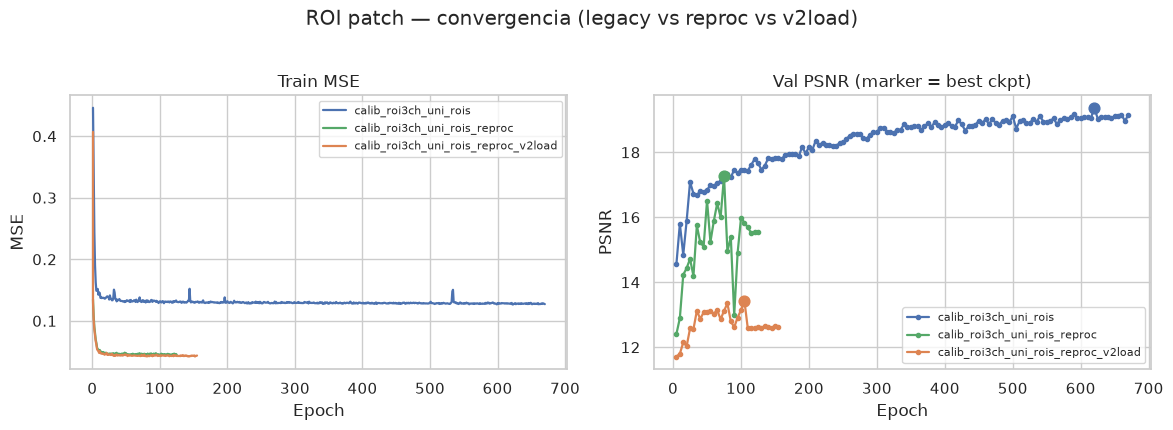

In [6]:
training_frames = {m: load_training_frames_for(COMPARISON[m]["exp"]) for m in MODES}
ckpt_rows = [
    checkpoint_summary_for_mode(m, COMPARISON[m], training_frames[m]) for m in MODES
]
ckpt_df = pd.DataFrame(ckpt_rows)
display(
    ckpt_df[
        [
            "mode_short",
            "split_profile",
            "norm_family",
            "image_norm",
            "best_epoch",
            "val_psnr",
            "val_ssim",
            "test_psnr_at_best",
            "test_ssim_at_best",
        ]
    ].round(4)
)


def _plot_train_domain(modes: list[str], title: str) -> None:
    if not modes:
        print(f"(sin experimentos para {title})")
        return
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for mode in modes:
        frames = training_frames[mode]
        color = MODE_COLORS[mode]
        label = MODE_SHORT[mode]
        if "loss_curve" in frames and not frames["loss_curve"].empty:
            loss = frames["loss_curve"]
            ycol = "MSE_loss" if "MSE_loss" in loss.columns else loss.columns[1]
            axes[0].plot(loss["Epoch"], loss[ycol], label=label, color=color, lw=1.6)
        if "validation" in frames and not frames["validation"].empty:
            val = frames["validation"]
            axes[1].plot(val["Epoch"], val["PSNR"], label=label, color=color, lw=1.6, marker="o", ms=3)
            best = int(ckpt_df.loc[ckpt_df["mode"] == mode, "best_epoch"].iloc[0])
            row = val[val["Epoch"] == best]
            if len(row):
                axes[1].scatter([best], [row["PSNR"].iloc[0]], color=color, s=60, zorder=5)
    axes[0].set_title("Train MSE")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("MSE")
    axes[0].legend(fontsize=8)
    axes[1].set_title("Val PSNR (marker = best ckpt)")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("PSNR")
    axes[1].legend(fontsize=8)
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    plt.show()


_plot_train_domain(ROI_PATCH_MODES, "ROI patch — convergencia (legacy vs reproc vs v2load)")


## 2. Reconstrucción en test (inferencia)

Fuente: `result/<exp>/inference/<run_id>/reconstruction_metrics.csv` (`split == test`).
Boxplots y medias **separados por dominio**.

recon test rows: 104

=== ROI patch (data_rois/) ===


,mode,mode_short,norm_family,PSNR_mean,PSNR_std,PSNR_count,SSIM_mean,SSIM_std,SSIM_count,PSNR_roi_mean,PSNR_roi_std,PSNR_roi_count,SSIM_roi_mean,SSIM_roi_std,SSIM_roi_count
0,calib_roi3ch_uni_rois,calib_roi3ch_uni_rois,legacy_data,19.1681,2.6802,36,0.2832,0.0933,36,22.0982,7.6155,36,0.8233,0.0683,36
1,calib_roi3ch_uni_rois_reproc,calib_roi3ch_uni_rois_reproc,reproc_legacy_zscore,17.2357,1.9538,34,0.1235,0.0338,34,21.3564,2.6245,34,0.7352,0.0384,34
2,calib_roi3ch_uni_rois_reproc_v2load,calib_roi3ch_uni_rois_reproc_v2load,reproc_v2load,13.3532,2.1784,34,0.0849,0.0272,34,16.6298,2.9130,34,0.6624,0.0344,34


/tmp/ipykernel_159497/231488663.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_159497/231488663.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_159497/231488663.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_159497/231488663.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


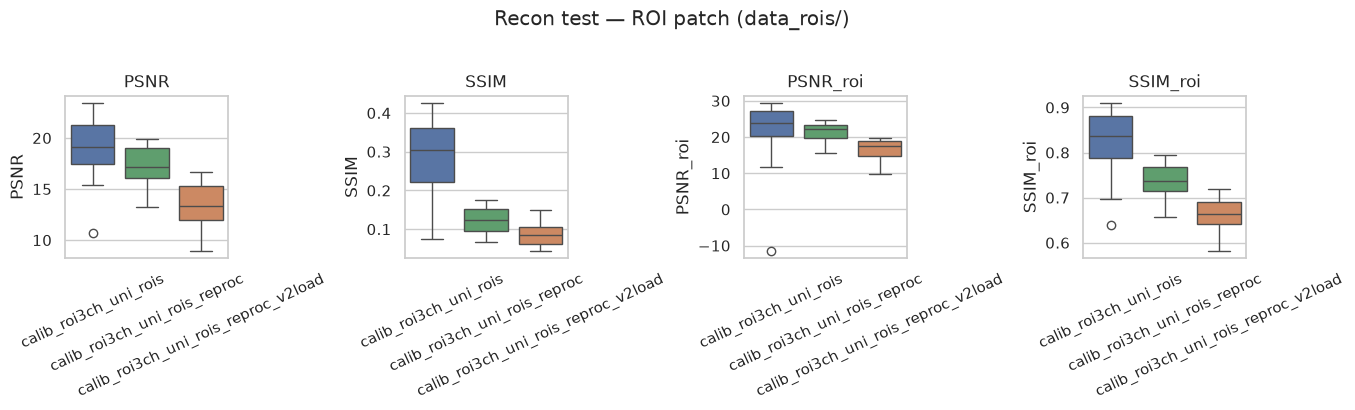

In [7]:
recon_parts = []
for mode in MODES:
    cfg = COMPARISON[mode]
    path = repo_root() / "result" / cfg["exp"] / "inference" / cfg["run_id"] / "reconstruction_metrics.csv"
    if not path.exists():
        print(f"SKIP recon {mode}: missing {path}")
        continue
    part = load_inference_reconstruction_for(cfg["exp"], cfg["run_id"], mode)
    part["mode_short"] = MODE_SHORT[mode]
    part["split_profile"] = COMPARISON[mode]["split_profile"]
    part["norm_family"] = COMPARISON[mode]["norm_family"]
    recon_parts.append(part)

recon_df = pd.concat(recon_parts, ignore_index=True) if recon_parts else pd.DataFrame()
print(f"recon test rows: {len(recon_df)}")


def _recon_summary(df: pd.DataFrame) -> pd.DataFrame:
    metric_cols = [c for c in ("PSNR", "SSIM", "PSNR_roi", "SSIM_roi") if c in df.columns]
    g = (
        df.groupby(["mode", "mode_short", "norm_family"], sort=False)[metric_cols]
        .agg(["mean", "std", "count"])
        .reset_index()
    )
    g.columns = [
        "_".join(c).strip("_") if isinstance(c, tuple) else c for c in g.columns.to_flat_index()
    ]
    return g


def plot_recon_boxes(modes: list[str], title: str) -> None:
    sub = subset_by_modes(recon_df, modes)
    if sub.empty:
        print(f"(sin recon para {title})")
        return
    metrics = [c for c in ("PSNR", "SSIM", "PSNR_roi", "SSIM_roi") if c in sub.columns]
    n = len(metrics)
    fig, axes = plt.subplots(1, n, figsize=(3.4 * n, 4.0), squeeze=False)
    order = short_labels_for_modes(modes, MODE_SHORT)
    palette = colors_for_modes(modes, MODE_COLORS)
    for ax, metric in zip(axes[0], metrics):
        sns.boxplot(
            data=sub,
            x="mode_short",
            y=metric,
            order=order,
            palette=dict(zip(order, palette)),
            ax=ax,
        )
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=25)
        ax.set_title(metric)
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    plt.show()


for domain_key, modes, domain_label in DOMAIN_BUCKETS:
    print(f"\n=== {domain_label} ===")
    display(_recon_summary(subset_by_modes(recon_df, modes)).round(4))
    plot_recon_boxes(modes, f"Recon test — {domain_label}")

## 3. Clasificación en test (latentes DDIM)

Fuente: `classification/classification_metrics.csv`. Métrica guía: **balanced_accuracy** y **roc_auc**.
En la tabla del mejor modelo por experimento se reportan también **precision** y **recall**.


classification rows: 18

=== ROI patch (data_rois/) ===


/tmp/ipykernel_159497/2022209534.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_159497/2022209534.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


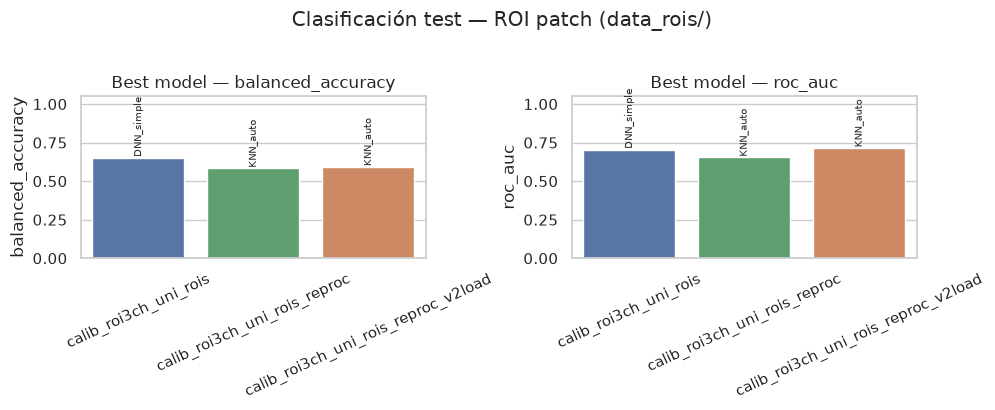

,mode_short,norm_family,model,balanced_accuracy,roc_auc,precision,recall,accuracy,f1
0,calib_roi3ch_uni_rois,legacy_data,DNN_simple,0.6524,0.7048,0.7500,0.5714,0.6389,0.6486
6,calib_roi3ch_uni_rois_reproc,reproc_legacy_zscore,KNN_auto,0.5821,0.6536,0.6333,0.9500,0.6471,0.7600
12,calib_roi3ch_uni_rois_reproc_v2load,reproc_v2load,KNN_auto,0.5929,0.7143,0.6429,0.9000,0.6471,0.7500


,mode_short,norm_family,model,balanced_accuracy,roc_auc,precision,recall,f1
0,calib_roi3ch_uni_rois,legacy_data,DNN_simple,0.6524,0.7048,0.7500,0.5714,0.6486
1,calib_roi3ch_uni_rois,legacy_data,KNN_K2,0.5714,0.5206,0.6296,0.8095,0.7083
2,calib_roi3ch_uni_rois,legacy_data,KNN_auto,0.5524,0.5413,0.6129,0.9048,0.7308
3,calib_roi3ch_uni_rois,legacy_data,LogisticRegression,0.5190,0.6571,0.5938,0.9048,0.7170
4,calib_roi3ch_uni_rois,legacy_data,SVM_linear,0.5095,0.6413,0.5882,0.9524,0.7273
5,calib_roi3ch_uni_rois,legacy_data,SVM_RBF,0.5000,0.3048,0.5833,1.0000,0.7368
6,calib_roi3ch_uni_rois_reproc,reproc_legacy_zscore,KNN_auto,0.5821,0.6536,0.6333,0.9500,0.7600
7,calib_roi3ch_uni_rois_reproc,reproc_legacy_zscore,DNN_simple,0.5464,0.5107,0.6429,0.4500,0.5294
8,calib_roi3ch_uni_rois_reproc,reproc_legacy_zscore,KNN_K2,0.5429,0.5875,0.6154,0.8000,0.6957
9,calib_roi3ch_uni_rois_reproc,reproc_legacy_zscore,SVM_RBF,0.5000,0.4821,0.5882,1.0000,0.7407


In [9]:
cls_parts = []
for mode in MODES:
    cfg = COMPARISON[mode]
    path = (
        repo_root()
        / "result"
        / cfg["exp"]
        / "inference"
        / cfg["run_id"]
        / "classification"
        / "classification_metrics.csv"
    )
    if not path.exists():
        print(f"SKIP cls {mode}: missing {path}")
        continue
    part = load_classification_metrics_for(cfg["exp"], cfg["run_id"], mode)
    part["mode_short"] = MODE_SHORT[mode]
    part["split_profile"] = COMPARISON[mode]["split_profile"]
    part["norm_family"] = COMPARISON[mode]["norm_family"]
    cls_parts.append(part)

cls_df = pd.concat(cls_parts, ignore_index=True) if cls_parts else pd.DataFrame()
print(f"classification rows: {len(cls_df)}")


def best_classifier_rows(df: pd.DataFrame) -> pd.DataFrame:
    """One row per mode: best model by balanced_accuracy (tie-break roc_auc)."""
    if df.empty:
        return df
    rows = []
    for mode, g in df.groupby("mode", sort=False):
        g2 = g.copy()
        g2["_auc"] = g2["roc_auc"] if "roc_auc" in g2.columns else np.nan
        g2 = g2.sort_values(["balanced_accuracy", "_auc"], ascending=False)
        rows.append(g2.iloc[0])
    return pd.DataFrame(rows).drop(columns=["_auc"], errors="ignore")


def plot_cls_bars(modes: list[str], title: str) -> None:
    sub = subset_by_modes(cls_df, modes)
    if sub.empty:
        print(f"(sin classification para {title})")
        return
    best = best_classifier_rows(sub)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    order = short_labels_for_modes(modes, MODE_SHORT)
    palette = colors_for_modes(modes, MODE_COLORS)
    for ax, metric in zip(axes, ("balanced_accuracy", "roc_auc")):
        if metric not in best.columns:
            continue
        sns.barplot(
            data=best,
            x="mode_short",
            y=metric,
            order=order,
            palette=dict(zip(order, palette)),
            ax=ax,
        )
        ax.set_ylim(0, 1.05)
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=25)
        ax.set_title(f"Best model — {metric}")
        for i, mode in enumerate(modes):
            row = best[best["mode"] == mode]
            if len(row):
                ax.text(
                    i,
                    float(row[metric].iloc[0]) + 0.02,
                    str(row["model"].iloc[0])[:10],
                    ha="center",
                    fontsize=7,
                    rotation=90,
                )
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    plt.show()
    display(
        best[
            [
                c
                for c in (
                    "mode_short",
                    "norm_family",
                    "model",
                    "balanced_accuracy",
                    "roc_auc",
                    "precision",
                    "recall",
                    "accuracy",
                    "f1",
                )
                if c in best.columns
            ]
        ].round(4)
    )


for domain_key, modes, domain_label in DOMAIN_BUCKETS:
    print(f"\n=== {domain_label} ===")
    plot_cls_bars(modes, f"Clasificación test — {domain_label}")
    display(
        subset_by_modes(cls_df, modes)[
            [
                c
                for c in (
                    "mode_short",
                    "norm_family",
                    "model",
                    "balanced_accuracy",
                    "roc_auc",
                    "precision",
                    "recall",
                    "f1",
                )
                if c in cls_df.columns
            ]
        ].round(4)
    )


## 4. Deltas vs baseline ROI + síntesis

Restar el baseline `calib_roi3ch_uni_rois` en reconstrucción (media test) y en el mejor clasificador.

Interpretación sugerida:
- **reproc + legacy z-score** ≈ efecto del cambio de NIfTI manteniendo la misma normalización.
- **reproc + v2load** ≈ efecto adicional de la política de carga (MRI `>0`, SPECT regional sin z-score).

Cuando existan los full-brain reproc, se podrá replicar el mismo esquema con baseline `calib_roi3ch_uni`.


In [10]:
def _mean_recon(mode: str) -> dict:
    sub = recon_df[recon_df["mode"] == mode]
    if sub.empty:
        return {}
    out = {}
    for c in ("PSNR", "SSIM", "PSNR_roi", "SSIM_roi"):
        if c in sub.columns:
            out[c] = float(sub[c].mean())
    return out


def _best_cls(mode: str) -> dict:
    sub = cls_df[cls_df["mode"] == mode]
    if sub.empty:
        return {}
    row = best_classifier_rows(sub).iloc[0]
    out = {
        "best_model": row["model"],
        "balanced_accuracy": float(row["balanced_accuracy"]),
        "roc_auc": float(row["roc_auc"]) if pd.notna(row.get("roc_auc", np.nan)) else float("nan"),
    }
    for metric in ("precision", "recall"):
        if metric in row.index and pd.notna(row[metric]):
            out[metric] = float(row[metric])
    return out


delta_rows = []
for profile, baseline_mode in DOMAIN_BASELINE.items():
    modes = [m for m in MODES if _mode_split_profile(m) == profile]
    if baseline_mode not in modes:
        print(f"Baseline {baseline_mode} no disponible en {profile}; se omiten deltas.")
        continue
    base_recon = _mean_recon(baseline_mode)
    base_cls = _best_cls(baseline_mode)
    for mode in modes:
        recon = _mean_recon(mode)
        cls = _best_cls(mode)
        row = {
            "domain": profile,
            "mode": mode,
            "mode_short": MODE_SHORT[mode],
            "norm_family": NORM_FAMILY[mode],
            "is_baseline": mode == baseline_mode,
            "baseline": baseline_mode,
        }
        for k, v in recon.items():
            row[k] = v
            row[f"d_{k}"] = v - base_recon[k] if k in base_recon else float("nan")
        for k, v in cls.items():
            row[k] = v
            if k in base_cls and k != "best_model":
                row[f"d_{k}"] = v - base_cls[k]
        # training checkpoint extras
        ck = ckpt_df[ckpt_df["mode"] == mode]
        if len(ck):
            row["best_epoch"] = int(ck["best_epoch"].iloc[0])
            row["val_psnr_ckpt"] = float(ck["val_psnr"].iloc[0])
        delta_rows.append(row)

delta_df = pd.DataFrame(delta_rows)
display_cols = [
    c
    for c in (
        "domain",
        "mode_short",
        "norm_family",
        "is_baseline",
        "PSNR",
        "d_PSNR",
        "SSIM",
        "d_SSIM",
        "PSNR_roi",
        "d_PSNR_roi",
        "balanced_accuracy",
        "d_balanced_accuracy",
        "roc_auc",
        "d_roc_auc",
        "precision",
        "d_precision",
        "recall",
        "d_recall",
        "best_model",
        "best_epoch",
    )
    if c in delta_df.columns
]
display(delta_df[display_cols].round(4))

# Compact narrative table: only non-baseline deltas
narrative = delta_df[~delta_df["is_baseline"]].copy() if not delta_df.empty else delta_df
if not narrative.empty:
    print("\nDeltas (variante − baseline de dominio):")
    show = [
        c
        for c in (
            "domain",
            "mode_short",
            "norm_family",
            "d_PSNR",
            "d_SSIM",
            "d_PSNR_roi",
            "d_balanced_accuracy",
            "d_roc_auc",
        )
        if c in narrative.columns
    ]
    display(narrative[show].round(4))


,domain,mode_short,norm_family,is_baseline,PSNR,d_PSNR,SSIM,d_SSIM,PSNR_roi,d_PSNR_roi,balanced_accuracy,d_balanced_accuracy,roc_auc,d_roc_auc,precision,d_precision,recall,d_recall,best_model,best_epoch
0,data_rois,calib_roi3ch_uni_rois,legacy_data,True,19.1681,0.0000,0.2832,0.0000,22.0982,0.0000,0.6524,0.0000,0.7048,0.0000,0.7500,0.0000,0.5714,0.0000,DNN_simple,620
1,data_rois,calib_roi3ch_uni_rois_reproc,reproc_legacy_zscore,False,17.2357,-1.9323,0.1235,-0.1597,21.3564,-0.7418,0.5821,-0.0702,0.6536,-0.0512,0.6333,-0.1167,0.9500,0.3786,KNN_auto,75
2,data_rois,calib_roi3ch_uni_rois_reproc_v2load,reproc_v2load,False,13.3532,-5.8149,0.0849,-0.1983,16.6298,-5.4683,0.5929,-0.0595,0.7143,0.0095,0.6429,-0.1071,0.9000,0.3286,KNN_auto,105



Deltas (variante − baseline de dominio):


,domain,mode_short,norm_family,d_PSNR,d_SSIM,d_PSNR_roi,d_balanced_accuracy,d_roc_auc
1,data_rois,calib_roi3ch_uni_rois_reproc,reproc_legacy_zscore,-1.9323,-0.1597,-0.7418,-0.0702,-0.0512
2,data_rois,calib_roi3ch_uni_rois_reproc_v2load,reproc_v2load,-5.8149,-0.1983,-5.4683,-0.0595,0.0095


In [11]:
REPORT_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
design_df.to_csv(REPORT_EXPORT_DIR / "design_matrix.csv", index=False)
ckpt_df.to_csv(REPORT_EXPORT_DIR / "training_checkpoint_summary.csv", index=False)
if not recon_df.empty:
    recon_df.to_csv(REPORT_EXPORT_DIR / "reconstruction_test_per_subject.csv", index=False)
    _recon_summary(recon_df).to_csv(REPORT_EXPORT_DIR / "reconstruction_test_summary.csv", index=False)
if not cls_df.empty:
    cls_df.to_csv(REPORT_EXPORT_DIR / "classification_metrics_all.csv", index=False)
    best_classifier_rows(cls_df).to_csv(REPORT_EXPORT_DIR / "classification_best_per_mode.csv", index=False)
if not delta_df.empty:
    delta_df.to_csv(REPORT_EXPORT_DIR / "deltas_vs_domain_baseline.csv", index=False)

print(f"Exportado a {REPORT_EXPORT_DIR}")
print("Archivos:", sorted(p.name for p in REPORT_EXPORT_DIR.iterdir()))

Exportado a /workspace/IL-CLDM/result/reproc_norm_comparison_summary
Archivos: ['classification_best_per_mode.csv', 'classification_metrics_all.csv', 'deltas_vs_domain_baseline.csv', 'design_matrix.csv', 'reconstruction_test_per_subject.csv', 'reconstruction_test_summary.csv', 'training_checkpoint_summary.csv']


## 5. Visualizaciones — corte SPECT de máximo brillo

Objetivo: mostrar el corte axial donde más se aprecia el uptake (estriado), como en el visor de referencia (imagen con ganglios brillantes; en ese visor figuraba como “corte 7”).

En los volúmenes ROI de este repo (`~96×112×114` / sintéticos `~105×102×102`) el estriado **no** está en el índice 7 del eje axial: suele caer cerca de la mitad del eje superior-inferior. Por eso el modo por defecto es:

- `SPECT_SLICE_MODE="brightest"`: elegir en el GT el corte axial (`axis=2`, orientación LAS) de **máxima suma de intensidad**, y proyectar el mismo índice relativo a cada sintético.
- `SPECT_SLICE_MODE="fixed"` + `SPECT_SLICE_INDEX=7`: forzar el índice 7 del visor (útil si abres un volumen ya recortado/reorientado).

Colormap `gray` para acercarse al visor. Misma fila = mismo sujeto; columnas = GT + cada modelo.


ROI patch (data_rois/): sujetos ['3554', '3191', '3759', '3593', '3332', '3182']
Slice policy: mode=brightest, axis=2, fixed_index=7


,ID,label_name,tier,psnr_mean
0,3554,control,peor_p10,17.341
1,3191,control,mediana_p50,18.631
2,3759,control,mejor_p90,19.629
3,3593,parkinson,peor_p10,13.264
4,3332,parkinson,mediana_p50,15.701
5,3182,parkinson,mejor_p90,16.346


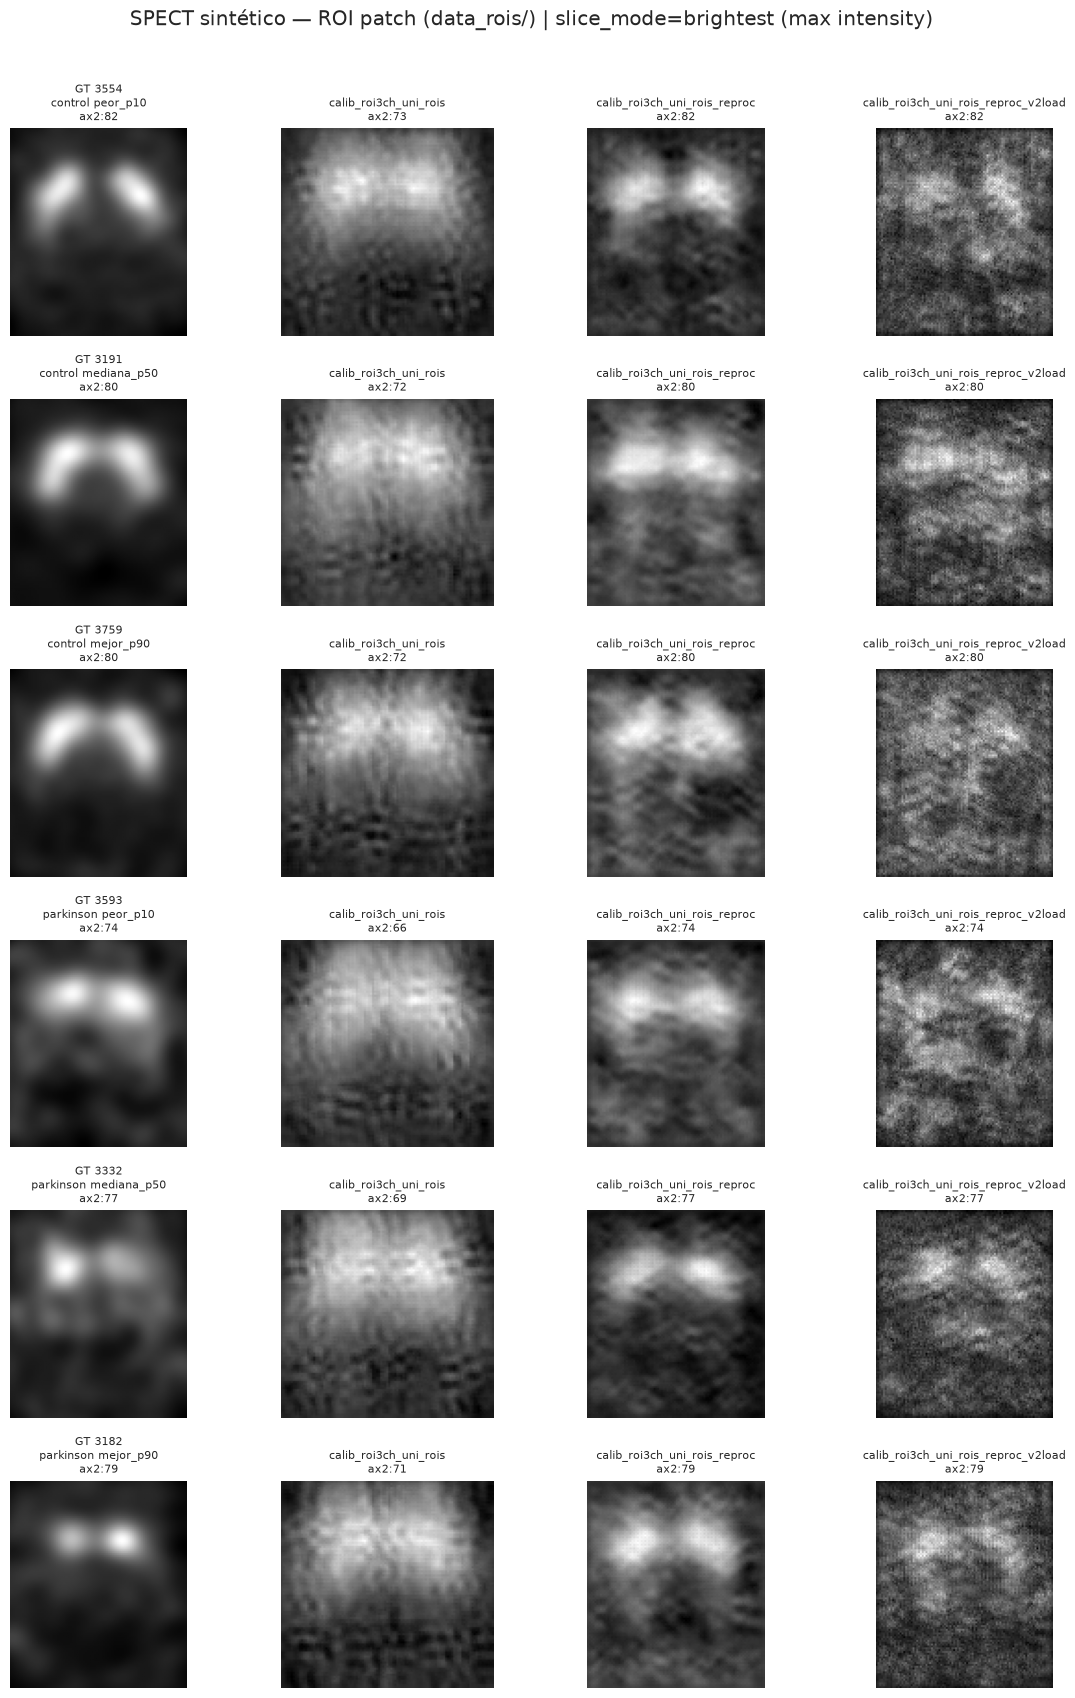

In [13]:
# --- Display slice policy (axial = axis 2 for LAS NIfTI) ---
SPECT_SLICE_AXIS = 2
SPECT_SLICE_MODE = "brightest"  # "brightest" | "fixed"
SPECT_SLICE_INDEX = 7  # used when mode == "fixed" (0-based; viewer "corte 7" often means this index if 0-based, or 6 if 1-based)
SPECT_CMAP = "gray"


def _slice2d(vol: np.ndarray, axis: int, index: int) -> np.ndarray:
    index = int(np.clip(index, 0, vol.shape[axis] - 1))
    return np.take(vol, index, axis=axis)


def brightest_slice_index(vol: np.ndarray, axis: int = SPECT_SLICE_AXIS) -> int:
    """Index of the axial slice with highest total intensity (striatum-dominant for DaT-like SPECT)."""
    scores = [
        float(np.maximum(_slice2d(vol, axis, i), 0).sum())
        for i in range(vol.shape[axis])
    ]
    return int(np.argmax(scores))


def resolve_display_slice(gt: np.ndarray, syn: np.ndarray | None = None) -> tuple[int, int]:
    """Return (gt_index, syn_index) on SPECT_SLICE_AXIS."""
    axis = SPECT_SLICE_AXIS
    if SPECT_SLICE_MODE == "fixed":
        gt_idx = int(np.clip(SPECT_SLICE_INDEX, 0, gt.shape[axis] - 1))
    else:
        gt_idx = brightest_slice_index(gt, axis)
    if syn is None:
        return gt_idx, gt_idx
    # Map proportionally if depth differs (legacy ROI 105^3 vs reproc 96x112x114).
    if syn.shape[axis] == gt.shape[axis]:
        syn_idx = gt_idx
    else:
        rel = gt_idx / max(gt.shape[axis] - 1, 1)
        syn_idx = int(np.clip(round(rel * (syn.shape[axis] - 1)), 0, syn.shape[axis] - 1))
    return gt_idx, syn_idx


def plot_comparison_grid(selected_df: pd.DataFrame, modes: list[str], *, title: str) -> None:
    if selected_df.empty or not modes:
        print(f"(sin sujetos/modos para {title})")
        return
    n_subj = len(selected_df)
    n_modes = len(modes)
    fig, axes = plt.subplots(
        n_subj,
        n_modes + 1,
        figsize=(3.0 * (n_modes + 1), 2.8 * n_subj),
        squeeze=False,
    )
    for r, row in enumerate(selected_df.itertuples(index=False)):
        sid = str(row.ID)
        label_name = getattr(row, "label_name", LABEL_NAMES.get(float(row.label), str(row.label)))
        tier = getattr(row, "tier", "")
        gt = load_gt_spect_for_mode(modes[0], sid)
        gt_idx, _ = resolve_display_slice(gt)
        gt_sl = np.rot90(_slice2d(gt, SPECT_SLICE_AXIS, gt_idx))
        axes[r, 0].imshow(gt_sl, cmap=SPECT_CMAP)
        axes[r, 0].set_title(
            f"GT {sid}\n{label_name} {tier}\nax{SPECT_SLICE_AXIS}:{gt_idx}",
            fontsize=8,
        )
        axes[r, 0].axis("off")
        for c_i, mode in enumerate(modes, start=1):
            cfg = COMPARISON[mode]
            try:
                syn = load_synthetic_volume_for(cfg["exp"], cfg["run_id"], sid)
            except Exception as exc:  # noqa: BLE001
                axes[r, c_i].set_title(f"{MODE_SHORT[mode]}\nmissing", fontsize=8)
                axes[r, c_i].axis("off")
                print(f"{mode}/{sid}: {exc}")
                continue
            _, syn_idx = resolve_display_slice(gt, syn)
            syn_sl = np.rot90(_slice2d(syn, SPECT_SLICE_AXIS, syn_idx))
            axes[r, c_i].imshow(syn_sl, cmap=SPECT_CMAP)
            axes[r, c_i].set_title(
                f"{MODE_SHORT[mode]}\nax{SPECT_SLICE_AXIS}:{syn_idx}",
                fontsize=8,
            )
            axes[r, c_i].axis("off")
    fig.suptitle(
        f"{title} | slice_mode={SPECT_SLICE_MODE}"
        + (f" index={SPECT_SLICE_INDEX}" if SPECT_SLICE_MODE == "fixed" else " (max intensity)"),
        y=1.01,
    )
    fig.tight_layout()
    plt.show()


for domain_key, modes, domain_label in DOMAIN_BUCKETS:
    if not modes or recon_df.empty:
        continue
    recon_by_mode = {m: recon_df[recon_df["mode"] == m].copy() for m in modes}
    recon_by_mode = {m: df for m, df in recon_by_mode.items() if not df.empty}
    if len(recon_by_mode) < 1:
        print(f"Sin recon para {domain_label}")
        continue
    selected = pick_stratified_subjects(recon_by_mode)
    print(f"{domain_label}: sujetos {selected['ID'].tolist()}")
    print(
        f"Slice policy: mode={SPECT_SLICE_MODE}, axis={SPECT_SLICE_AXIS}, "
        f"fixed_index={SPECT_SLICE_INDEX}"
    )
    display(selected[["ID", "label_name", "tier", "psnr_mean"]].round(3))
    plot_comparison_grid(
        selected,
        list(recon_by_mode.keys()),
        title=f"SPECT sintético — {domain_label}",
    )


## 6. Apéndice — A/B full-brain: `calib_fb_clamp` vs `calib_fb_v2`

> **Aclaración:** esta sección es sobre **full-brain** (`data/`, crop legacy → latente `(40,48,40)`), **no** sobre ROI patch (`data_rois/`). No mezclar métricas de imagen ni conclusiones con las secciones 1–5.

Pregunta experimental distinta a reproc/norm:

| Clave | Rol | Contenido |
|-------|-----|-----------|
| `calib_fb_clamp` | **baseline** | Recipe calib + ROI 3ch + t uniforme + **clamp ±4**; EMA legacy, attn`(4,)`, sin FiLM |
| `calib_fb_v2` | tratamiento | Clamp ±4 + label dropout 0.15 + **EMA warmup 0.9→0.995** + **attn`(5,)`** + **FiLM** |

Métrica guía: balanced accuracy / AUC del latente DDIM. Export bajo `result/reproc_norm_comparison_summary/fb_ab_*`.


In [14]:
# --- Full-brain A/B (independent of ROI WAVE_ORDER) ---
FB_WAVE_ORDER = ("calib_fb_clamp", "calib_fb_v2")
FB_BASELINE = "calib_fb_clamp"
FB_EXPORT_PREFIX = "fb_ab"

fb_pool = available_comparison()
FB_COMPARISON = _with_registry_meta({k: fb_pool[k] for k in FB_WAVE_ORDER if k in fb_pool})
# Ensure short labels / meta even if not in NORM_FAMILY
for k, cfg in list(FB_COMPARISON.items()):
    cfg["short_label"] = _REGISTRY[k].get("short_label", k)
    cfg["label"] = _REGISTRY[k].get("label", cfg.get("label", k))
    cfg["split_profile"] = _REGISTRY[k].get("split_profile", "primary")
    cfg["norm_family"] = "fullbrain_ab"
    cfg["image_norm"] = image_norm_for_mode(k)

FB_MODES = list(FB_COMPARISON.keys())
FB_MISSING = [m for m in FB_WAVE_ORDER if m not in FB_COMPARISON]
FB_SHORT = {m: FB_COMPARISON[m]["short_label"] for m in FB_MODES}
FB_COLORS = {
    "calib_fb_clamp": "#4C72B0",
    "calib_fb_v2": "#DD8452",
}

print("=== §6 Full-brain A/B (NO ROI) ===")
print(f"Disponibles: {FB_MODES}")
if FB_MISSING:
    print(f"FALTAN: {FB_MISSING}")
for m in FB_MODES:
    cfg = FB_COMPARISON[m]
    print(f"  [{FB_SHORT[m]}] {cfg['exp']} / {cfg['run_id']}  (split_profile={cfg['split_profile']})")
if FB_BASELINE not in FB_MODES:
    raise RuntimeError(f"Baseline {FB_BASELINE} no disponible; no se puede hacer el A/B.")
if any(_mode_split_profile(m) == "data_rois" for m in FB_MODES):
    raise RuntimeError("§6 debe ser solo full-brain; se detectó split_profile=data_rois.")


=== §6 Full-brain A/B (NO ROI) ===
Disponibles: ['calib_fb_clamp', 'calib_fb_v2']
  [calib_fb_clamp] exp_nm_s2_frozen_calib_fb_clamp / calib_fb_clamp  (split_profile=primary)
  [calib_fb_v2] exp_nm_s2_frozen_calib_fb_v2 / calib_fb_v2  (split_profile=primary)


### 6.1 Convergencia (full-brain)


,mode_short,best_epoch,val_psnr,val_ssim,test_psnr_at_best,test_ssim_at_best,last_epoch
0,calib_fb_clamp,175,16.0674,0.3946,16.1337,0.3948,225
1,calib_fb_v2,35,15.6822,0.3763,15.6005,0.3711,85


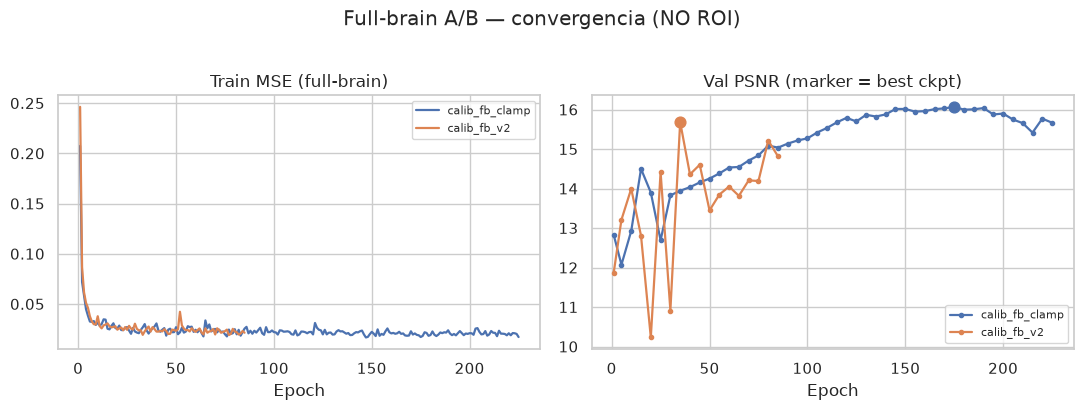

In [15]:
fb_training = {m: load_training_frames_for(FB_COMPARISON[m]["exp"]) for m in FB_MODES}
fb_ckpt_rows = [checkpoint_summary_for_mode(m, FB_COMPARISON[m], fb_training[m]) for m in FB_MODES]
fb_ckpt_df = pd.DataFrame(fb_ckpt_rows)
display(
    fb_ckpt_df[
        [
            c
            for c in (
                "mode_short",
                "best_epoch",
                "val_psnr",
                "val_ssim",
                "test_psnr_at_best",
                "test_ssim_at_best",
                "last_epoch",
            )
            if c in fb_ckpt_df.columns
        ]
    ].round(4)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for mode in FB_MODES:
    frames = fb_training[mode]
    color = FB_COLORS.get(mode, "#333333")
    label = FB_SHORT[mode]
    if "loss_curve" in frames and not frames["loss_curve"].empty:
        loss = frames["loss_curve"]
        ycol = "MSE_loss" if "MSE_loss" in loss.columns else loss.columns[1]
        axes[0].plot(loss["Epoch"], loss[ycol], label=label, color=color, lw=1.6)
    if "validation" in frames and not frames["validation"].empty:
        val = frames["validation"]
        axes[1].plot(val["Epoch"], val["PSNR"], label=label, color=color, lw=1.6, marker="o", ms=3)
        best = int(fb_ckpt_df.loc[fb_ckpt_df["mode"] == mode, "best_epoch"].iloc[0])
        row = val[val["Epoch"] == best]
        if len(row):
            axes[1].scatter([best], [row["PSNR"].iloc[0]], color=color, s=60, zorder=5)
axes[0].set_title("Train MSE (full-brain)")
axes[0].set_xlabel("Epoch")
axes[0].legend(fontsize=8)
axes[1].set_title("Val PSNR (marker = best ckpt)")
axes[1].set_xlabel("Epoch")
axes[1].legend(fontsize=8)
fig.suptitle("Full-brain A/B — convergencia (NO ROI)", y=1.02)
fig.tight_layout()
plt.show()


### 6.2 Reconstrucción test (full-brain)


FB recon test rows: 68


,mode,mode_short,PSNR_mean,PSNR_std,PSNR_count,SSIM_mean,SSIM_std,SSIM_count,PSNR_roi_mean,PSNR_roi_std,PSNR_roi_count,SSIM_roi_mean,SSIM_roi_std,SSIM_roi_count
0,calib_fb_clamp,calib_fb_clamp,16.0056,1.1738,34,0.3907,0.0638,34,17.8154,1.4416,34,0.7044,0.0367,34
1,calib_fb_v2,calib_fb_v2,15.6934,0.9636,34,0.3834,0.0446,34,17.6784,1.3292,34,0.6868,0.0376,34


/tmp/ipykernel_159497/1600899567.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_159497/1600899567.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_159497/1600899567.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_159497/1600899567.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


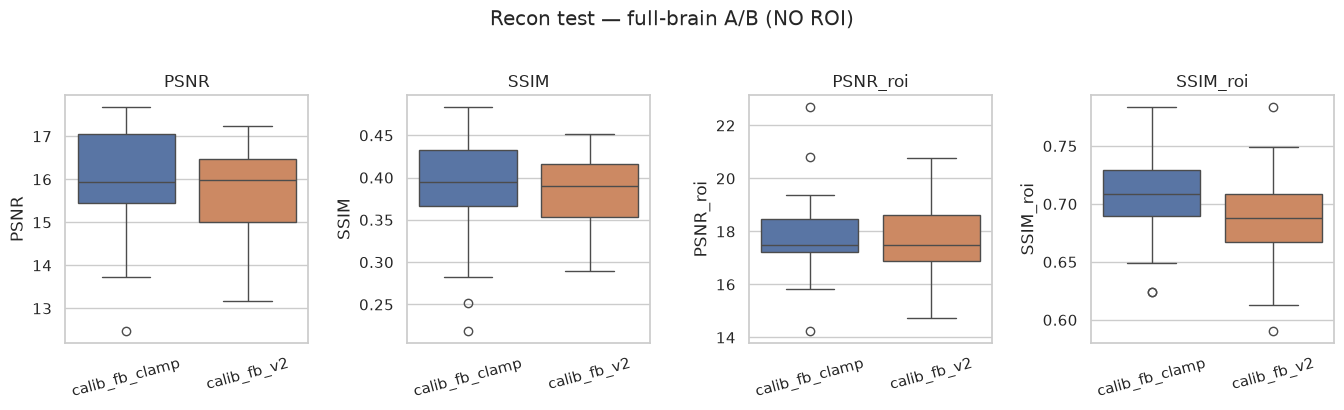

In [16]:
fb_recon_parts = []
for mode in FB_MODES:
    cfg = FB_COMPARISON[mode]
    path = repo_root() / "result" / cfg["exp"] / "inference" / cfg["run_id"] / "reconstruction_metrics.csv"
    if not path.exists():
        print(f"SKIP recon {mode}: missing {path}")
        continue
    part = load_inference_reconstruction_for(cfg["exp"], cfg["run_id"], mode)
    part["mode_short"] = FB_SHORT[mode]
    fb_recon_parts.append(part)

fb_recon_df = pd.concat(fb_recon_parts, ignore_index=True) if fb_recon_parts else pd.DataFrame()
print(f"FB recon test rows: {len(fb_recon_df)}")

if not fb_recon_df.empty:
    metric_cols = [c for c in ("PSNR", "SSIM", "PSNR_roi", "SSIM_roi") if c in fb_recon_df.columns]
    fb_recon_summary = (
        fb_recon_df.groupby(["mode", "mode_short"], sort=False)[metric_cols]
        .agg(["mean", "std", "count"])
        .reset_index()
    )
    fb_recon_summary.columns = [
        "_".join(c).strip("_") if isinstance(c, tuple) else c
        for c in fb_recon_summary.columns.to_flat_index()
    ]
    display(fb_recon_summary.round(4))

    order = [FB_SHORT[m] for m in FB_MODES if m in fb_recon_df["mode"].unique()]
    palette = {FB_SHORT[m]: FB_COLORS[m] for m in FB_MODES}
    n = len(metric_cols)
    fig, axes = plt.subplots(1, n, figsize=(3.4 * n, 4.0), squeeze=False)
    for ax, metric in zip(axes[0], metric_cols):
        sns.boxplot(
            data=fb_recon_df,
            x="mode_short",
            y=metric,
            order=order,
            palette=palette,
            ax=ax,
        )
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=15)
        ax.set_title(metric)
    fig.suptitle("Recon test — full-brain A/B (NO ROI)", y=1.02)
    fig.tight_layout()
    plt.show()


### 6.3 Clasificación test (full-brain)

Incluye precision y recall en la tabla del mejor modelo.


FB classification rows: 8


,mode_short,model,balanced_accuracy,roc_auc,precision,recall,accuracy,f1
0,calib_fb_clamp,DNN_simple,0.5893,0.5429,0.6522,0.75,0.6176,0.6977
4,calib_fb_v2,DNN_simple,0.5857,0.5357,0.6667,0.60,0.5882,0.6316


,mode_short,model,balanced_accuracy,roc_auc,precision,recall,f1
0,calib_fb_clamp,DNN_simple,0.5893,0.5429,0.6522,0.75,0.6977
1,calib_fb_clamp,KNN_auto,0.5286,0.5250,0.6087,0.70,0.6512
2,calib_fb_clamp,KNN_K2,0.5286,0.5464,0.6087,0.70,0.6512
3,calib_fb_clamp,LogisticRegression,0.5286,0.6071,0.6087,0.70,0.6512
4,calib_fb_v2,DNN_simple,0.5857,0.5357,0.6667,0.60,0.6316
5,calib_fb_v2,KNN_auto,0.5643,0.6107,0.6364,0.70,0.6667
6,calib_fb_v2,KNN_K2,0.5286,0.5821,0.6087,0.70,0.6512
7,calib_fb_v2,LogisticRegression,0.5286,0.4821,0.6087,0.70,0.6512


/tmp/ipykernel_159497/539855977.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fb_best, x="mode_short", y=metric, order=order, palette=palette, ax=ax)
/tmp/ipykernel_159497/539855977.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fb_best, x="mode_short", y=metric, order=order, palette=palette, ax=ax)


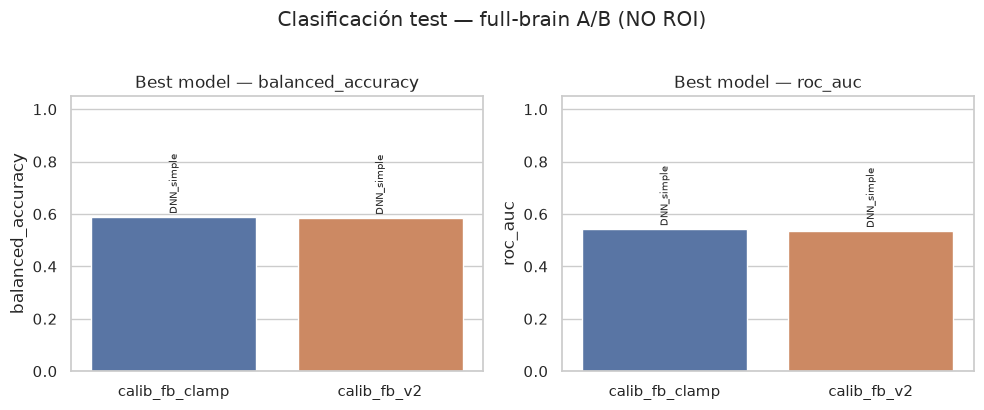

In [17]:
fb_cls_parts = []
for mode in FB_MODES:
    cfg = FB_COMPARISON[mode]
    path = (
        repo_root()
        / "result"
        / cfg["exp"]
        / "inference"
        / cfg["run_id"]
        / "classification"
        / "classification_metrics.csv"
    )
    if not path.exists():
        print(f"SKIP cls {mode}: missing {path}")
        continue
    part = load_classification_metrics_for(cfg["exp"], cfg["run_id"], mode)
    part["mode_short"] = FB_SHORT[mode]
    fb_cls_parts.append(part)

fb_cls_df = pd.concat(fb_cls_parts, ignore_index=True) if fb_cls_parts else pd.DataFrame()
print(f"FB classification rows: {len(fb_cls_df)}")

if not fb_cls_df.empty:
    fb_best = best_classifier_rows(fb_cls_df)
    display(
        fb_best[
            [
                c
                for c in (
                    "mode_short",
                    "model",
                    "balanced_accuracy",
                    "roc_auc",
                    "precision",
                    "recall",
                    "accuracy",
                    "f1",
                )
                if c in fb_best.columns
            ]
        ].round(4)
    )
    display(
        fb_cls_df[
            [
                c
                for c in (
                    "mode_short",
                    "model",
                    "balanced_accuracy",
                    "roc_auc",
                    "precision",
                    "recall",
                    "f1",
                )
                if c in fb_cls_df.columns
            ]
        ].round(4)
    )

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    order = [FB_SHORT[m] for m in FB_MODES]
    palette = {FB_SHORT[m]: FB_COLORS[m] for m in FB_MODES}
    for ax, metric in zip(axes, ("balanced_accuracy", "roc_auc")):
        if metric not in fb_best.columns:
            continue
        sns.barplot(data=fb_best, x="mode_short", y=metric, order=order, palette=palette, ax=ax)
        ax.set_ylim(0, 1.05)
        ax.set_xlabel("")
        ax.set_title(f"Best model — {metric}")
        for i, mode in enumerate(FB_MODES):
            row = fb_best[fb_best["mode"] == mode]
            if len(row):
                ax.text(
                    i,
                    float(row[metric].iloc[0]) + 0.02,
                    str(row["model"].iloc[0])[:12],
                    ha="center",
                    fontsize=7,
                    rotation=90,
                )
    fig.suptitle("Clasificación test — full-brain A/B (NO ROI)", y=1.02)
    fig.tight_layout()
    plt.show()


### 6.4 Deltas vs baseline `calib_fb_clamp` (full-brain)


In [18]:
def _fb_mean_recon(mode: str) -> dict:
    sub = fb_recon_df[fb_recon_df["mode"] == mode]
    if sub.empty:
        return {}
    return {c: float(sub[c].mean()) for c in ("PSNR", "SSIM", "PSNR_roi", "SSIM_roi") if c in sub.columns}


def _fb_best_cls(mode: str) -> dict:
    sub = fb_cls_df[fb_cls_df["mode"] == mode]
    if sub.empty:
        return {}
    row = best_classifier_rows(sub).iloc[0]
    out = {
        "best_model": row["model"],
        "balanced_accuracy": float(row["balanced_accuracy"]),
        "roc_auc": float(row["roc_auc"]) if pd.notna(row.get("roc_auc", np.nan)) else float("nan"),
    }
    for metric in ("precision", "recall"):
        if metric in row.index and pd.notna(row[metric]):
            out[metric] = float(row[metric])
    return out


fb_delta_rows = []
base_recon = _fb_mean_recon(FB_BASELINE)
base_cls = _fb_best_cls(FB_BASELINE)
for mode in FB_MODES:
    recon = _fb_mean_recon(mode)
    cls = _fb_best_cls(mode)
    row = {
        "domain": "full-brain",
        "mode": mode,
        "mode_short": FB_SHORT[mode],
        "is_baseline": mode == FB_BASELINE,
        "baseline": FB_BASELINE,
    }
    for k, v in recon.items():
        row[k] = v
        row[f"d_{k}"] = v - base_recon[k] if k in base_recon else float("nan")
    for k, v in cls.items():
        row[k] = v
        if k in base_cls and k != "best_model":
            row[f"d_{k}"] = v - base_cls[k]
    ck = fb_ckpt_df[fb_ckpt_df["mode"] == mode]
    if len(ck):
        row["best_epoch"] = int(ck["best_epoch"].iloc[0])
        row["val_psnr_ckpt"] = float(ck["val_psnr"].iloc[0])
    fb_delta_rows.append(row)

fb_delta_df = pd.DataFrame(fb_delta_rows)
fb_display_cols = [
    c
    for c in (
        "mode_short",
        "is_baseline",
        "PSNR",
        "d_PSNR",
        "SSIM",
        "d_SSIM",
        "PSNR_roi",
        "d_PSNR_roi",
        "balanced_accuracy",
        "d_balanced_accuracy",
        "roc_auc",
        "d_roc_auc",
        "precision",
        "d_precision",
        "recall",
        "d_recall",
        "best_model",
        "best_epoch",
    )
    if c in fb_delta_df.columns
]
display(fb_delta_df[fb_display_cols].round(4))

REPORT_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
fb_ckpt_df.to_csv(REPORT_EXPORT_DIR / f"{FB_EXPORT_PREFIX}_training_checkpoint.csv", index=False)
if not fb_recon_df.empty:
    fb_recon_df.to_csv(REPORT_EXPORT_DIR / f"{FB_EXPORT_PREFIX}_reconstruction_test.csv", index=False)
if not fb_cls_df.empty:
    fb_cls_df.to_csv(REPORT_EXPORT_DIR / f"{FB_EXPORT_PREFIX}_classification_all.csv", index=False)
    best_classifier_rows(fb_cls_df).to_csv(
        REPORT_EXPORT_DIR / f"{FB_EXPORT_PREFIX}_classification_best.csv", index=False
    )
fb_delta_df.to_csv(REPORT_EXPORT_DIR / f"{FB_EXPORT_PREFIX}_deltas_vs_clamp.csv", index=False)
print(f"Export FB A/B → {REPORT_EXPORT_DIR} ({FB_EXPORT_PREFIX}_*)")


,mode_short,is_baseline,PSNR,d_PSNR,SSIM,d_SSIM,PSNR_roi,d_PSNR_roi,balanced_accuracy,d_balanced_accuracy,roc_auc,d_roc_auc,precision,d_precision,recall,d_recall,best_model,best_epoch
0,calib_fb_clamp,True,16.0056,0.0000,0.3907,0.0000,17.8154,0.0000,0.5893,0.0000,0.5429,0.0000,0.6522,0.0000,0.75,0.00,DNN_simple,175
1,calib_fb_v2,False,15.6934,-0.3121,0.3834,-0.0074,17.6784,-0.1371,0.5857,-0.0036,0.5357,-0.0071,0.6667,0.0145,0.60,-0.15,DNN_simple,35


Export FB A/B → /workspace/IL-CLDM/result/reproc_norm_comparison_summary (fb_ab_*)


### 6.5 Visualizaciones full-brain (corte de máximo brillo)

Misma política de corte que §5 (`brightest` axial). Dominio **full-brain** (`data/`), no `data_rois/`.


Full-brain sujetos: ['3188', '3191', '3554', '3824', '3120', '3108']


,ID,label_name,tier,psnr_mean
0,3188,control,peor_p10,16.377
1,3191,control,mediana_p50,16.774
2,3554,control,mejor_p90,17.054
3,3824,parkinson,peor_p10,14.304
4,3120,parkinson,mediana_p50,15.284
5,3108,parkinson,mejor_p90,16.365


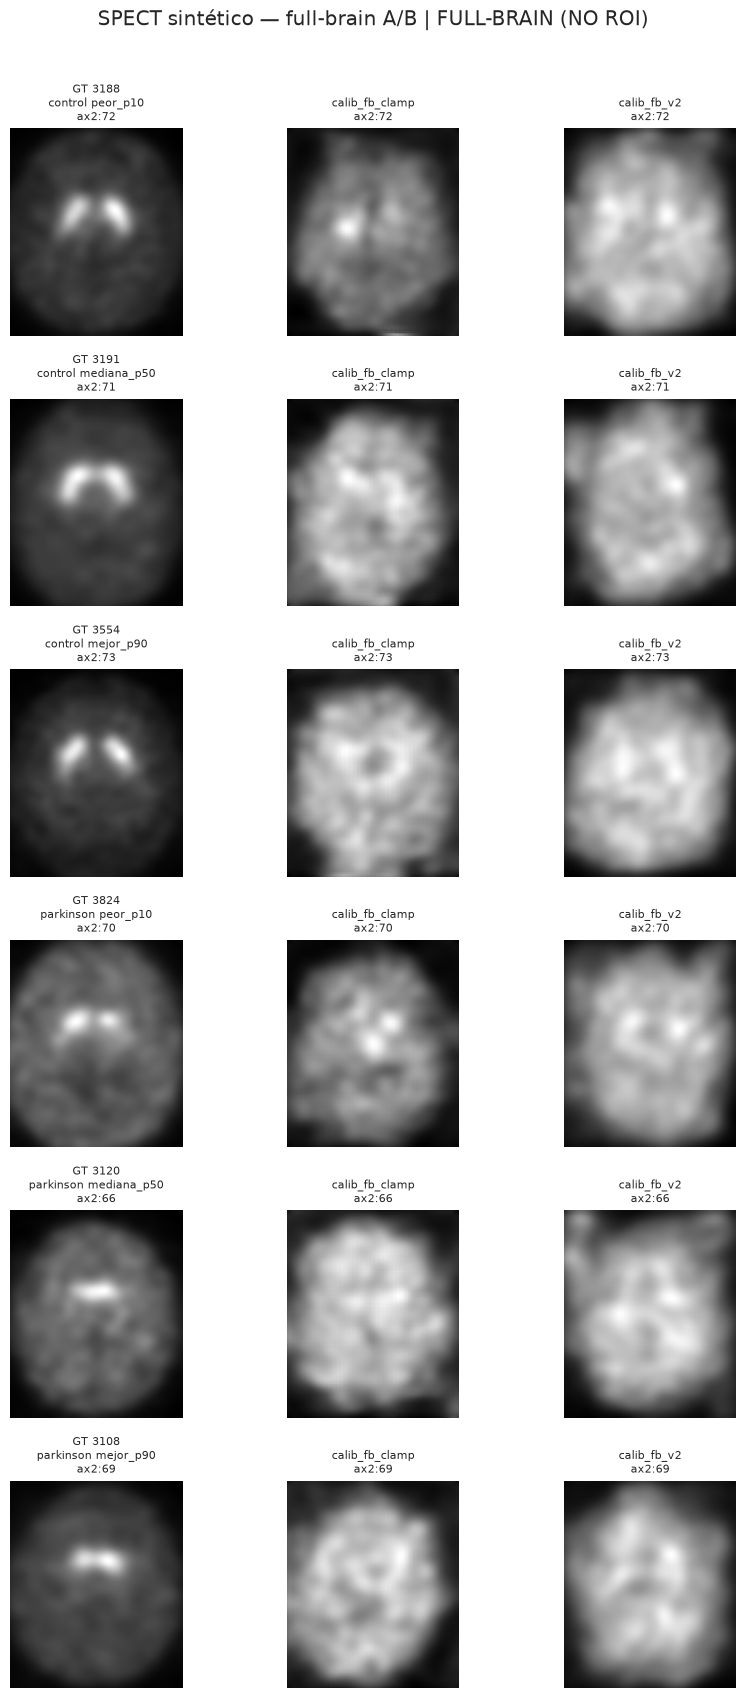

In [19]:
# Reuse slice helpers from §5 if already executed; otherwise define minimal fallbacks.
if "brightest_slice_index" not in globals():
    SPECT_SLICE_AXIS = 2
    SPECT_SLICE_MODE = "brightest"
    SPECT_SLICE_INDEX = 7
    SPECT_CMAP = "gray"

    def _slice2d(vol, axis, index):
        index = int(np.clip(index, 0, vol.shape[axis] - 1))
        return np.take(vol, index, axis=axis)

    def brightest_slice_index(vol, axis=SPECT_SLICE_AXIS):
        scores = [
            float(np.maximum(_slice2d(vol, axis, i), 0).sum())
            for i in range(vol.shape[axis])
        ]
        return int(np.argmax(scores))

    def resolve_display_slice(gt, syn=None):
        axis = SPECT_SLICE_AXIS
        if SPECT_SLICE_MODE == "fixed":
            gt_idx = int(np.clip(SPECT_SLICE_INDEX, 0, gt.shape[axis] - 1))
        else:
            gt_idx = brightest_slice_index(gt, axis)
        if syn is None:
            return gt_idx, gt_idx
        if syn.shape[axis] == gt.shape[axis]:
            return gt_idx, gt_idx
        rel = gt_idx / max(gt.shape[axis] - 1, 1)
        syn_idx = int(np.clip(round(rel * (syn.shape[axis] - 1)), 0, syn.shape[axis] - 1))
        return gt_idx, syn_idx


def plot_fb_comparison_grid(selected_df: pd.DataFrame, modes: list[str], *, title: str) -> None:
    if selected_df.empty or not modes:
        print("(sin sujetos FB)")
        return
    n_subj = len(selected_df)
    fig, axes = plt.subplots(
        n_subj, len(modes) + 1, figsize=(3.0 * (len(modes) + 1), 2.8 * n_subj), squeeze=False
    )
    for r, row in enumerate(selected_df.itertuples(index=False)):
        sid = str(row.ID)
        label_name = getattr(row, "label_name", LABEL_NAMES.get(float(row.label), str(row.label)))
        tier = getattr(row, "tier", "")
        gt = load_gt_spect_for_mode(modes[0], sid)  # full-brain via split_profile=primary
        gt_idx, _ = resolve_display_slice(gt)
        axes[r, 0].imshow(np.rot90(_slice2d(gt, SPECT_SLICE_AXIS, gt_idx)), cmap=SPECT_CMAP)
        axes[r, 0].set_title(
            f"GT {sid}\n{label_name} {tier}\nax{SPECT_SLICE_AXIS}:{gt_idx}", fontsize=8
        )
        axes[r, 0].axis("off")
        for c_i, mode in enumerate(modes, start=1):
            cfg = FB_COMPARISON[mode]
            try:
                syn = load_synthetic_volume_for(cfg["exp"], cfg["run_id"], sid)
            except Exception as exc:  # noqa: BLE001
                axes[r, c_i].set_title(f"{FB_SHORT[mode]}\nmissing", fontsize=8)
                axes[r, c_i].axis("off")
                print(f"{mode}/{sid}: {exc}")
                continue
            _, syn_idx = resolve_display_slice(gt, syn)
            axes[r, c_i].imshow(
                np.rot90(_slice2d(syn, SPECT_SLICE_AXIS, syn_idx)), cmap=SPECT_CMAP
            )
            axes[r, c_i].set_title(
                f"{FB_SHORT[mode]}\nax{SPECT_SLICE_AXIS}:{syn_idx}", fontsize=8
            )
            axes[r, c_i].axis("off")
    fig.suptitle(f"{title} | FULL-BRAIN (NO ROI)", y=1.01)
    fig.tight_layout()
    plt.show()


if fb_recon_df.empty:
    print("Sin recon FB para visualización.")
else:
    fb_recon_by_mode = {m: fb_recon_df[fb_recon_df["mode"] == m].copy() for m in FB_MODES}
    fb_recon_by_mode = {m: df for m, df in fb_recon_by_mode.items() if not df.empty}
    fb_selected = pick_stratified_subjects(fb_recon_by_mode)
    print(f"Full-brain sujetos: {fb_selected['ID'].tolist()}")
    display(fb_selected[["ID", "label_name", "tier", "psnr_mean"]].round(3))
    plot_fb_comparison_grid(
        fb_selected,
        list(fb_recon_by_mode.keys()),
        title="SPECT sintético — full-brain A/B",
    )


## Notas de lectura

1. La parte principal de este notebook está **acotada a ROI patch** porque faltan `calib_roi3ch_uni_reproc` y `…_reproc_v2load` full-brain; sin ellos el baseline `calib_roi3ch_uni` no es comparable ahí.
2. El **§6** es un apéndice aparte: A/B full-brain `calib_fb_clamp` vs `calib_fb_v2` (clamp + mejoras EMA/attn/FiLM). **No** es el mismo eje que reproc/norm ROI.
3. Para reactivar el factorial full-brain reproc: entrenar/inferir esos runs y ampliar `WAVE_ORDER`.
4. Métrica guía clínica habitual: **AUC / balanced accuracy latente**, no PSNR.
